# Notebook 08 — Capacity Sweep

**Hyperparameter-optimisation experiment · Soccer Event Transformer · Track A model family**

| Item | Content |
|---|---|
| **Question** | How does validation NLL change when the capacity of the Track A Transformer is increased along depth, context length, head count and width? |
| **Purpose of this notebook** | Train a staged grid of capacity configurations under the unchanged Track A training procedure, record one row per run, and produce the shortlist of architectures that receive a training-hyperparameter search. |
| **Starting point** | The Track A reference model: decoder-only Transformer, 2 layers, 2 heads, d_model 128, d_ff 512, K = 16, T300 player encoding, pre-action possession features, learning rate 3e-4, weight decay 0.1, 30-epoch budget with early stopping. |
| **What is varied** | Number of layers, context length K, number of heads, d_model and d_ff. |
| **What is held fixed** | Dataset, preprocessing, feature set, action labels, splits, player threshold, window stride, learning rate, weight decay, batch size, warm-up, schedule, gradient clipping, early stopping and every evaluation function. |
| **Seeds** | Screening seeds 0 and 1 for every configuration. |
| **Test data** | Not used. The test split stays locked. |
| **Outputs** | `results/08_capacity_runs.csv`, `results/08_capacity_summary.csv`, `results/08_profile.csv`, `results/08_top_configs.json`, `results/08_summary.json`, training curves and capacity plots in `figures/`. |


In [ ]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every notebook of this experiment)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
import math
import copy
import hashlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# Root of the existing Track A project (the folder that contains src/, artifacts/, runs/, results/).
PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Existing Track A outputs. These are read.
EXISTING_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
EXISTING_RUNS_DIR = EXISTING_DIR / "runs"
EXISTING_RESULTS_DIR = EXISTING_DIR / "results"
EXISTING_FROZEN_CONFIG = EXISTING_DIR / "config" / "frozen_config.json"

OPT_DIR = EXISTING_DIR / "experiments" / "hyperparameter_optimisation"
RUNS_DIR = OPT_DIR / "runs"
RESULTS_DIR = OPT_DIR / "results"
FIGURES_DIR = OPT_DIR / "figures"
CONFIG_DIR = OPT_DIR / "config"
MANIFEST_DIR = OPT_DIR / "manifests"
LOG_DIR = OPT_DIR / "logs"
for folder in [RUNS_DIR, RESULTS_DIR, FIGURES_DIR, CONFIG_DIR, MANIFEST_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = MANIFEST_DIR / "experiment_manifest.jsonl"


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("Track A project (read-only):", EXISTING_DIR)
print("Experiment outputs:", OPT_DIR)

Mounted at /content/drive
Colab: True | RUN_MODE: full
Track A project (read-only): /content/drive/MyDrive/soccer_mi/track_a
Experiment outputs: /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation


In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import importlib

# The Track A modules are imported. Every run of this experiment therefore
# uses exactly the model definition, training loop and metric code that produced Track A.
import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline
import src.training as training
import src.analysis as analysis
for module in [data, batching, metrics, model_module, mlp_baseline, training, analysis]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    raise RuntimeError("BLOCKED: full-mode training requires a GPU. In Colab: Runtime > Change runtime type > GPU.")

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()

with open(EXISTING_FROZEN_CONFIG) as handle:
    TRACK_A_FROZEN = json.load(handle)

# Fixed by Track A.
ENCODING = TRACK_A_FROZEN["encoding"]
POSSESSION_FEATURES = TRACK_A_FROZEN["possession_features"]
STRIDE = TRACK_A_FROZEN["stride"]

# The Track A operating point, used as the reference configuration below.
BASE_LAYERS = TRACK_A_FROZEN["model"]["n_layers"]
BASE_HEADS = TRACK_A_FROZEN["model"]["n_heads"]
BASE_D_MODEL = TRACK_A_FROZEN["model"]["d_model"]
BASE_D_FF = TRACK_A_FROZEN["model"]["d_ff"]
BASE_CONTEXT = TRACK_A_FROZEN["context_length"]
BASE_LR = TRACK_A_FROZEN["training"]["learning_rate"]
BASE_WD = TRACK_A_FROZEN["training"]["weight_decay"]
EPOCH_BUDGET = TRACK_A_FROZEN["training"]["max_epochs"]

print("Events:", len(events), "| device:", DEVICE)
print("Track A reference configuration:",
      f"L{BASE_LAYERS} H{BASE_HEADS} d_model {BASE_D_MODEL} d_ff {BASE_D_FF} K{BASE_CONTEXT}",
      f"| lr {BASE_LR:g} wd {BASE_WD:g} | epoch budget {EPOCH_BUDGET}")

Events: 658905 | device: cuda
Track A reference configuration: L2 H2 d_model 128 d_ff 512 K16 | lr 0.0003 wd 0.1 | epoch budget 30


In [ ]:
# -----------------
# Helper functions
# -----------------

SHORT_NAME = {"batch_size": "bs", "warmup_fraction": "wu"}


def transformer_config(seed, n_layers, n_heads, context_length, d_model=None, d_ff=None,
                       learning_rate=None, weight_decay=None, max_epochs=None):
    """Build a run configuration used by the Track A"""
    model = {"n_layers": n_layers, "n_heads": n_heads,
             "d_model": BASE_D_MODEL if d_model is None else d_model,
             "d_ff": BASE_D_FF if d_ff is None else d_ff}
    training_settings = {"learning_rate": BASE_LR if learning_rate is None else learning_rate,
                         "weight_decay": BASE_WD if weight_decay is None else weight_decay,
                         "max_epochs": EPOCH_BUDGET if max_epochs is None else max_epochs}
    return {"model_type": "transformer", "encoding": ENCODING, "possession_features": POSSESSION_FEATURES,
            "context_length": context_length, "stride": STRIDE, "seed": seed,
            "model": model, "training": training_settings}


def architecture_label(config):
    """Readable architecture name, e.g. L4-H2-K16-D128-F512."""
    model = config["model"]
    return (f"L{model['n_layers']}-H{model['n_heads']}-K{config['context_length']}"
            f"-D{model['d_model']}-F{model['d_ff']}")


def variant_tag(training_settings):
    """Sub-folder for training settings that training.run_name_for() does not encode.

    run_name_for() encodes the learning rate, weight decay, architecture, context length and
    seed, but not the batch size or the warm-up fraction. To prevent runs that differ only in those
    two settings (batch size or the warm-up fraction) to be written to the same folder.
    """
    parts = []
    for key in ["batch_size", "warmup_fraction"]:
        if key in training_settings and training_settings[key] != training.DEFAULT_TRAINING[key]:
            parts.append(f"{SHORT_NAME[key]}{training_settings[key]:g}")
    return "_".join(parts) if parts else "base"


_BUNDLES = {}


def bundle_for(context_length):
    """Encoded data and evaluation views for one context length."""
    if context_length not in _BUNDLES:
        _BUNDLES[context_length] = training.prepare_data(
            events, ARTIFACTS_DIR, ENCODING, POSSESSION_FEATURES, context_length, STRIDE, DEVICE, RUN_MODE)
    return _BUNDLES[context_length]


def parameter_count(config):
    """Total parameters of a configuration, without training."""
    model = training.build_model(config, bundle_for(config["context_length"])["vocabulary_sizes"])
    return model_module.count_parameters(model)["total"]


def run_one(config, extra_training=None, keep_every_epoch=False, verbose=True):
    """Train one configuration (or reload it if its folder already holds a finished run).

    Returns (run_dir, final_results).
    """
    config = copy.deepcopy(config)
    if extra_training:
        config["training"].update(extra_training)
    runs_root = RUNS_DIR / variant_tag(config["training"])
    runs_root.mkdir(parents=True, exist_ok=True)
    result = training.train_run(config, bundle_for(config["context_length"]), runs_root,
                                MANIFEST_PATH, keep_every_epoch=keep_every_epoch, verbose=verbose)
    return runs_root / training.run_name_for(config), result


def result_row(config, run_dir, result, group=""):
    """One flat record per run, required in later notebooks."""
    val = result["val_metrics"]
    training_settings = result["training_settings"]
    return {
        "group": group,
        "architecture": architecture_label(config),
        "n_layers": config["model"]["n_layers"],
        "n_heads": config["model"]["n_heads"],
        "d_head": config["model"]["d_model"] // config["model"]["n_heads"],
        "d_model": config["model"]["d_model"],
        "d_ff": config["model"]["d_ff"],
        "context_length": config["context_length"],
        "learning_rate": training_settings["learning_rate"],
        "weight_decay": training_settings["weight_decay"],
        "batch_size": training_settings["batch_size"],
        "warmup_fraction": training_settings["warmup_fraction"],
        "seed": config["seed"],
        "parameters": result["parameter_counts"]["total"],
        "trainable_parameters": result["parameter_counts"].get("trainable", result["parameter_counts"]["total"]),
        "val_nll": val["nll"],
        "val_accuracy": val["accuracy"],
        "val_macro_f1": val["macro_f1"],
        "val_top3": val["top3_accuracy"],
        "val_top5": val["top5_accuracy"],
        "val_ece": val["ece"],
        "train_nll": result["train_nll"],
        "best_epoch": result["best_epoch"],
        "epochs_run": result["epochs_run"],
        "stopped_early": result["stopped_early"],
        "diverged": result["diverged"],
        "runtime_seconds": result["runtime_seconds"],
        "run_dir": str(run_dir),
        "run_name": result["run_name"],
    }


def append_results(rows, csv_path):
    """Append run records to a CSV, keeping one row per run name and variant folder."""
    table = pd.DataFrame(rows)
    if Path(csv_path).exists():
        table = pd.concat([pd.read_csv(csv_path), table], ignore_index=True)
    table = table.drop_duplicates(subset=["run_dir"], keep="last").reset_index(drop=True)
    table.to_csv(csv_path, index=False)
    return table


def seed_level_to_config_level(table):
    """Average the seed-level records of each configuration into one row per configuration."""
    keys = ["group", "architecture", "n_layers", "n_heads", "d_head", "d_model", "d_ff",
            "context_length", "learning_rate", "weight_decay", "batch_size", "warmup_fraction",
            "parameters"]
    summary = table.groupby(keys, as_index=False, sort=False).agg(
        n_seeds=("seed", "count"),
        val_nll=("val_nll", "mean"),
        val_nll_sd=("val_nll", "std"),
        val_accuracy=("val_accuracy", "mean"),
        val_accuracy_sd=("val_accuracy", "std"),
        val_macro_f1=("val_macro_f1", "mean"),
        val_top3=("val_top3", "mean"),
        val_top5=("val_top5", "mean"),
        val_ece=("val_ece", "mean"),
        train_nll=("train_nll", "mean"),
        best_epoch=("best_epoch", "mean"),
        runtime_seconds=("runtime_seconds", "mean"),
    )
    return summary.sort_values("val_nll").reset_index(drop=True)


def run_dirs_for(table, **conditions):
    """All run directories in a results table that match the given column values."""
    selected = table
    for column, value in conditions.items():
        selected = selected[selected[column] == value]
    return [Path(path) for path in selected["run_dir"]]


print("Helper functions defined.")

Helper functions defined.


## 1. Terms used in this notebook

| Term | Meaning here |
|---|---|
| **Layer** | One Transformer block: causal self-attention followed by an MLP, each inside a pre-LayerNorm residual connection. |
| **Head** | One independent attention computation inside a layer. With d_model fixed, adding heads divides the same attention width into more, narrower heads; the parameter count does not change. |
| **Context length (K)** | Number of consecutive events in one input window. The prediction at position *i* can use at most the *i* earlier events of the same window. |
| **d_model** | Width of the residual stream. |
| **d_ff** | Width of the hidden layer inside each block's MLP. |
| **Validation NLL** | Mean negative log-likelihood of the observed action on the validation split, with each event scored exactly once (in the window where it has the most history before it). Primary metric. |
| **Seed** | The number that fixes weight initialisation and the order of training windows. Two seeds of one configuration differ only by chance. |
| **Seed SD** | Standard deviation of validation NLL across the seeds of one configuration. It measures training noise only; it is not a confidence interval over matches. |
| **Configuration** | One architecture together with one set of training hyperparameters. A configuration is trained once per seed. |
| **Run** | One training of one configuration with one seed. |
| **Capacity** | A loose term for how much the model can represent. It is measured here by parameter count, depth and context length, which do not increase together, so each is reported separately. |

## 2. Settings inherited from Track A

Only model and training hyperparameters are changed in this experiment. Everything else is read from the files that describe the frozen Track A model, so no value is typed by hand:

* player encoding, possession features, window stride and epoch budget come from the frozen Track A configuration (`config/frozen_config.json`);
* the model code, training loop, checkpoint rule, evaluation view and metric functions are the modules in `src/`, imported without modification;
* the event table is `artifacts/events_prepared.parquet`, the same file the Track A model was trained on.

**Check.** The dataset fingerprint (SHA-256) is compared with the one recorded when the Track A configuration was frozen. A mismatch stops the notebook: results obtained on a different event table would not be comparable with the Track A model.

In [ ]:
inherited = pd.DataFrame([
    ("player encoding", ENCODING, "config/frozen_config.json"),
    ("possession features", POSSESSION_FEATURES, "config/frozen_config.json"),
    ("window stride", STRIDE, "config/frozen_config.json"),
    ("epoch budget", EPOCH_BUDGET, "config/frozen_config.json"),
    ("learning rate (starting point)", BASE_LR, "config/frozen_config.json"),
    ("weight decay (starting point)", BASE_WD, "config/frozen_config.json"),
    ("batch size / warm-up / schedule / clipping / precision",
     "256 windows, 5% warm-up, cosine to 10% of peak, clip 1.0, fp32", "src/training.py (DEFAULT_TRAINING)"),
    ("early stopping", "patience 5 epochs on validation NLL", "src/training.py"),
    ("checkpoint rule", "lowest validation NLL (best.pt)", "src/training.py"),
    ("activation / normalisation", "GELU / pre-LayerNorm", "src/model.py"),
    ("output classes", model_module.ModelConfig.n_actions, "src/model.py"),
], columns=["setting", "value", "source"])

recorded_hash = TRACK_A_FROZEN["dataset_sha256"]
current_hash = json.load(open(ARTIFACTS_DIR / "dataset_hash.json"))["sha256"]
if recorded_hash != current_hash:
    raise RuntimeError("BLOCKED: the event table differs from the one Track A was frozen on.")
print("Dataset SHA-256 matches the frozen Track A configuration:", current_hash)
inherited

Dataset SHA-256 matches the frozen Track A configuration: 2fe8019fb59f8060f77ae0b81eba3df2077a3fd50c02f601ed7f401b3855fc5b


,setting,value,source
0,player encoding,T300,config/frozen_config.json
1,possession features,pre_action,config/frozen_config.json
2,window stride,8,config/frozen_config.json
3,epoch budget,30,config/frozen_config.json
4,learning rate (starting point),0.0003,config/frozen_config.json
5,weight decay (starting point),0.1,config/frozen_config.json
6,batch size / warm-up / schedule / clipping / p...,"256 windows, 5% warm-up, cosine to 10% of peak...",src/training.py (DEFAULT_TRAINING)
7,early stopping,patience 5 epochs on validation NLL,src/training.py
8,checkpoint rule,lowest validation NLL (best.pt),src/training.py
9,activation / normalisation,GELU / pre-LayerNorm,src/model.py


## 3. Code compatibility with the Track A model

**Why this matters.** Results from this experiment are only comparable with the Track A model if the code here computes the same model as the code that trained it. Two checks are made before any training:

1. **Architecture.** The primary Track A checkpoint is loaded into a model built by the current code with `strict=True`. Loading fails if any parameter name or shape differs.
2. **Numerical.** The validation logits of that checkpoint are recomputed and compared with the logits stored when it was trained.

The source files and the Track A result files are also fingerprinted, so that the end of the notebook can check that no Track A file was modified.

In [ ]:
with open(EXISTING_RESULTS_DIR / "06_validation_report.json") as handle:
    track_a_validation_report = json.load(handle)
TRACK_A_PRIMARY_DIR = EXISTING_RUNS_DIR / track_a_validation_report["primary_run"]
with open(TRACK_A_PRIMARY_DIR / "run_config.json") as handle:
    track_a_primary_config = json.load(handle)

reference_bundle = bundle_for(track_a_primary_config["context_length"])
reference_model = training.build_model(track_a_primary_config, reference_bundle["vocabulary_sizes"]).to(DEVICE)
reference_model.load_state_dict(torch.load(TRACK_A_PRIMARY_DIR / "best.pt", map_location=DEVICE), strict=True)

recomputed_logits, _, recomputed_rows = training.predict_view(reference_model, reference_bundle, "val")
stored = np.load(TRACK_A_PRIMARY_DIR / "val_predictions.npz")
order_new = np.argsort(recomputed_rows)
order_stored = np.argsort(stored["event_rows"])
same_events = bool(np.array_equal(recomputed_rows[order_new], stored["event_rows"][order_stored]))
max_difference = float(np.abs(recomputed_logits[order_new] - stored["logits"][order_stored]).max())

compatibility = {
    "track A primary run": TRACK_A_PRIMARY_DIR.name,
    "checkpoint loads with strict=True": True,
    "parameter count (current code)": model_module.count_parameters(reference_model)["total"],
    "parameter count (recorded)": analysis.load_final_results(TRACK_A_PRIMARY_DIR)["parameter_counts"]["total"],
    "same validation events": same_events,
    "max |recomputed - stored logit|": max_difference,
}
for key, value in compatibility.items():
    print(f"{key:36s} {value}")
if not same_events or compatibility["parameter count (current code)"] != compatibility["parameter count (recorded)"]:
    raise RuntimeError("BLOCKED: the current code does not reproduce the existing Track A model.")

track A primary run                  transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s104
checkpoint loads with strict=True    True
parameter count (current code)       514575
parameter count (recorded)           514575
same validation events               True
max |recomputed - stored logit|      0.0


In [ ]:
source_fingerprints = {}
for file in sorted((PROJECT_DIR / "src").glob("*.py")):
    source_fingerprints[file.name] = file_sha256(file)

existing_snapshot = {}
for folder in [EXISTING_RESULTS_DIR, EXISTING_DIR / "config"]:
    for file in sorted(folder.rglob("*")):
        if file.is_file():
            existing_snapshot[str(file.relative_to(EXISTING_DIR))] = file_sha256(file)

snapshot_path = MANIFEST_DIR / "track_a_snapshot.json"
if not snapshot_path.exists():
    training.save_json(snapshot_path, existing_snapshot)
training.save_json(MANIFEST_DIR / "src_fingerprints.json", source_fingerprints)
training.save_json(MANIFEST_DIR / "code_compatibility_check.json", compatibility)
training.save_json(MANIFEST_DIR / "environment.json", training.environment_info())
print(f"Fingerprinted {len(source_fingerprints)} source files and {len(existing_snapshot)} Track A result files.")
print("Environment:", json.dumps(training.environment_info(), indent=2, default=str))

Fingerprinted 9 source files and 35 Track A result files.
Environment: {
  "python": "3.13.15",
  "torch": "2.11.0+cu128",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "cuda_available": true,
  "gpu": "Tesla T4",
  "cuda": "12.8"
}


This experiment runs on the same model definition, data encoding and evaluation view as the Track A model. Differences reported below come from the changed hyperparameters, not from a change in the code.

## 4. Training keys from existing code

We will be experimenting with: the architecture (layers, heads, d_model, d_ff), the context length, and the training keys that `src.training.train_run` accepts through `run_config["training"]` (learning rate, weight decay, batch size, warm-up fraction, minimum learning-rate ratio, gradient clipping, patience, epoch budget). The cell below prints those keys from the module, and checks that the model contains no dropout module.

In [ ]:
print("Training keys accepted by src/training.py:")
for key, value in training.DEFAULT_TRAINING.items():
    print(f"  {key:18s} default = {value}")

has_dropout = any("dropout" in name.lower() for name, _ in
                  training.build_model(transformer_config(0, BASE_LAYERS, BASE_HEADS, BASE_CONTEXT),
                                       bundle_for(BASE_CONTEXT)["vocabulary_sizes"]).named_modules())
print("\nDropout modules present in the model:", has_dropout)

Training keys accepted by src/training.py:
  batch_size         default = 256
  max_epochs         default = 30
  warmup_fraction    default = 0.05
  min_lr_ratio       default = 0.1
  grad_clip          default = 1.0
  patience           default = 5
  beta1              default = 0.9
  beta2              default = 0.999
  eps                default = 1e-08
  learning_rate      default = 0.0003
  weight_decay       default = 0.1

Dropout modules present in the model: False


## 5. Design of the sweep

A full factorial grid over depth, context length, head count and width would need several hundred runs. The sweep is therefore staged: each stage varies one aspect of capacity and holds the others at the configuration with the lowest mean validation NLL so far.

| Stage | Varied | Held at | Configurations |
|---|---|---|---|
| **A — depth × context** | layers ∈ {2, 4, 6, 8} × K ∈ {8, 16, 32, 64} | 2 heads, d_model 128, d_ff 512 (Track A values) | 16 |
| **B — heads** | heads ∈ {1, 2, 4, 8} | best (layers, K) from stage A | 4 (3 new) |
| **C — width** | (d_model, d_ff) ∈ {(128, 512), (128, 1024), (192, 768), (256, 512), (256, 1024)} | best (layers, K, heads) from stages A and B | 5 (4 new) |

**Limitation of a staged design.** A greedy path can miss an interaction between two axes. Two things limit that risk here.
1. stage A crosses depth with context length instead of fixing one of them, because context length had the largest effect of any architectural variable in the Track A architecture experiments; the interaction is measured.
2. the final choice is not the single winner of this path: several shortlisted architectures are later re-trained with more seeds before anything is selected.

**Seeds.** Every configuration is trained with two screening seeds, 0 and 1. Two seeds are enough to catch a configuration whose apparent advantage disappears on a second initialisation. They are not enough to show that one configuration is better than another, so the ranking produced here only decides where to spend the remaining compute. Seeds 0 and 1 are disjoint from the final-training seeds 100–104.

d_model must be divisible by the number of heads; this is checked when each configuration is built.

In [ ]:
STAGE_A_LAYERS = [2, 4, 6, 8]
STAGE_A_CONTEXT = [8, 16, 32, 64]
STAGE_B_HEADS = [1, 2, 4, 8]
STAGE_C_WIDTHS = [(128, 512), (128, 1024), (192, 768), (256, 512), (256, 1024)]
SCREENING_SEEDS = [0, 1]

CAPACITY_RUNS_CSV = RESULTS_DIR / "08_capacity_runs.csv"
CAPACITY_SUMMARY_CSV = RESULTS_DIR / "08_capacity_summary.csv"
PROFILE_CSV = RESULTS_DIR / "08_profile.csv"
TOP_CONFIGS_JSON = RESULTS_DIR / "08_top_configs.json"

print("Stage A configurations:", len(STAGE_A_LAYERS) * len(STAGE_A_CONTEXT))
print("Screening seeds:", SCREENING_SEEDS)
print("Results are written to:", CAPACITY_RUNS_CSV)

Stage A configurations: 16
Screening seeds: [0, 1]
Results are written to: /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/results/08_capacity_runs.csv


## 6. Cost estimate before training

**What this step does.** Two quantities decide whether the sweep fits in the available Colab compute: the peak GPU memory of the largest configuration, and the time of one training epoch. Both are measured from parameter counts, because attention cost grows with the square of the context length.

Each architecture is built once and run for six forward/backward steps at the training batch size (the first step is dropped from the timing because it includes one-off allocation). Peak allocated GPU memory and mean step time are recorded. Mean step time × steps per epoch × epoch budget gives a worst-case runtime per configuration. For stages B and C, whose architectures are only known after stage A, the largest stage A setting (8 layers, K = 64) is used as a cost upper bound.

In [ ]:
def profile_configuration(config, n_steps=6):
    # Peak GPU memory and mean step time for one configuration
    bundle = bundle_for(config["context_length"])
    training.set_seed(0)
    model = training.build_model(config, bundle["vocabulary_sizes"]).to(DEVICE)
    optimizer = training.make_optimizer(model, dict(training.DEFAULT_TRAINING, **config["training"]))
    batch_size = dict(training.DEFAULT_TRAINING, **config["training"])["batch_size"]
    windows = bundle["train_windows"]

    if DEVICE == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    model.train()
    step_times = []
    for step in range(n_steps):
        batch = windows[step * batch_size:(step + 1) * batch_size]
        if len(batch) == 0:
            break
        inputs, batch_targets = bundle["encoded"].batch(batch)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        started = time.time()
        loss = model_module.compute_loss(model(inputs), batch_targets)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        step_times.append(time.time() - started)

    peak_memory_mb = torch.cuda.max_memory_allocated() / 1e6 if DEVICE == "cuda" else float("nan")
    steps_per_epoch = math.ceil(len(windows) / batch_size)

    # the first step includes one-off allocation, so it is dropped when more than one was timed
    mean_step = float(np.mean(step_times[1:] if len(step_times) > 1 else step_times))
    del model, optimizer
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return {"peak_gpu_memory_mb": peak_memory_mb, "mean_step_seconds": mean_step,
            "steps_per_epoch": steps_per_epoch,
            "estimated_epoch_seconds": mean_step * steps_per_epoch,
            "estimated_worst_case_minutes": mean_step * steps_per_epoch * EPOCH_BUDGET / 60}

In [ ]:
planned_configs = []
for n_layers in STAGE_A_LAYERS:
    for context_length in STAGE_A_CONTEXT:
        planned_configs.append(("A depth x context", transformer_config(0, n_layers, BASE_HEADS, context_length)))
planned_configs.append(("B heads (cost upper bound)",
                        transformer_config(0, max(STAGE_A_LAYERS), BASE_HEADS, max(STAGE_A_CONTEXT))))
for d_model, d_ff in STAGE_C_WIDTHS:
    planned_configs.append(("C width (cost upper bound)",
                            transformer_config(0, max(STAGE_A_LAYERS), BASE_HEADS, max(STAGE_A_CONTEXT),
                                               d_model=d_model, d_ff=d_ff)))

# The stage B and C entries above use the largest stage A setting purely as a cost upper bound:
# the actual stage B and C architectures are decided after stage A has been trained
profile_rows = []
for group, config in planned_configs:
    measured = profile_configuration(config)
    profile_rows.append({"group": group, "architecture": architecture_label(config),
                         "parameters": parameter_count(config), **measured})
profile_table = pd.DataFrame(profile_rows).drop_duplicates(subset=["group", "architecture"]).reset_index(drop=True)
profile_table.to_csv(PROFILE_CSV, index=False)

total_runs = len(STAGE_A_LAYERS) * len(STAGE_A_CONTEXT) + (len(STAGE_B_HEADS) - 1) + (len(STAGE_C_WIDTHS) - 1)
worst_case_hours = profile_table["estimated_worst_case_minutes"].mean() * total_runs * len(SCREENING_SEEDS) / 60
print(f"Configurations to train: {total_runs}")
print(f"Total runs (x{len(SCREENING_SEEDS)} seeds): {total_runs * len(SCREENING_SEEDS)}")
print(f"Largest peak GPU memory measured: {profile_table['peak_gpu_memory_mb'].max():.0f} MB")
print(f"Worst-case total runtime if no run stops early: {worst_case_hours:.1f} hours")
profile_table.round(3)

Configurations to train: 23
Total runs (x2 seeds): 46
Largest peak GPU memory measured: 2973 MB
Worst-case total runtime if no run stops early: 5.8 hours


,group,architecture,parameters,peak_gpu_memory_mb,mean_step_seconds,steps_per_epoch,estimated_epoch_seconds,estimated_worst_case_minutes
0,A depth x context,L2-H2-K8-D128-F512,513551,278.804,0.012,256,3.007,1.503
1,A depth x context,L2-H2-K16-D128-F512,514575,328.082,0.015,254,3.710,1.855
2,A depth x context,L2-H2-K32-D128-F512,516623,535.609,0.021,250,5.309,2.655
3,A depth x context,L2-H2-K64-D128-F512,520719,852.866,0.038,241,9.157,4.579
4,A depth x context,L4-H2-K8-D128-F512,910095,562.861,0.013,256,3.451,1.725
5,A depth x context,L4-H2-K16-D128-F512,911119,648.665,0.016,254,4.057,2.028
6,A depth x context,L4-H2-K32-D128-F512,913167,809.793,0.023,250,5.782,2.891
7,A depth x context,L4-H2-K64-D128-F512,917263,1144.964,0.046,241,11.060,5.530
8,A depth x context,L6-H2-K8-D128-F512,1306639,603.090,0.018,256,4.505,2.252
9,A depth x context,L6-H2-K16-D128-F512,1307663,723.300,0.024,254,6.066,3.033


**What the table shows.** One row per profiled architecture: peak GPU memory during a training step, mean optimiser-step time, steps per epoch, and the runtime if the whole 30-epoch budget were used.



## 7. Stage A — depth and context length

Sixteen configurations: four depths crossed with four context lengths, at 2 heads, d_model 128 and d_ff 512. Parameter count rises with depth and only slightly with context length, because each window position has its own learned positional embedding (for example 910,095 parameters at 4 layers and K = 8 against 917,263 at 4 layers and K = 64).

In [ ]:
stage_a_rows = []
for n_layers in STAGE_A_LAYERS:
    for context_length in STAGE_A_CONTEXT:
        for seed in SCREENING_SEEDS:
            config = transformer_config(seed, n_layers, BASE_HEADS, context_length)
            run_dir, result = run_one(config)
            stage_a_rows.append(result_row(config, run_dir, result, group="A depth x context"))
            print(f"  {architecture_label(config)} seed {seed}: "
                  f"val NLL {result['val_metrics']['nll']:.4f} | acc {result['val_metrics']['accuracy']:.4f}")

capacity_table = append_results(stage_a_rows, CAPACITY_RUNS_CSV)
stage_a_summary = seed_level_to_config_level(capacity_table[capacity_table["group"] == "A depth x context"])
stage_a_summary[["architecture", "n_layers", "context_length", "parameters", "n_seeds",
                 "val_nll", "val_nll_sd", "val_accuracy", "val_macro_f1", "best_epoch",
                 "runtime_seconds"]].round(4)

[transformer_T300_pre_action_L2_H2_D128_F512_K8_g-all_lr0.0003_wd0.1_s0] epoch  1 | train loss 1.6470 | val NLL 1.1150 | val acc 0.5842 | val macro-F1 0.4862 | 4s
[transformer_T300_pre_action_L2_H2_D128_F512_K8_g-all_lr0.0003_wd0.1_s0] epoch  2 | train loss 1.0245 | val NLL 0.9772 | val acc 0.5985 | val macro-F1 0.5328 | 6s
[transformer_T300_pre_action_L2_H2_D128_F512_K8_g-all_lr0.0003_wd0.1_s0] epoch  3 | train loss 0.9506 | val NLL 0.9466 | val acc 0.6072 | val macro-F1 0.5392 | 4s
[transformer_T300_pre_action_L2_H2_D128_F512_K8_g-all_lr0.0003_wd0.1_s0] epoch  4 | train loss 0.9249 | val NLL 0.9296 | val acc 0.6100 | val macro-F1 0.5417 | 4s
[transformer_T300_pre_action_L2_H2_D128_F512_K8_g-all_lr0.0003_wd0.1_s0] epoch  5 | train loss 0.9087 | val NLL 0.9186 | val acc 0.6161 | val macro-F1 0.5487 | 6s
[transformer_T300_pre_action_L2_H2_D128_F512_K8_g-all_lr0.0003_wd0.1_s0] epoch  6 | train loss 0.8972 | val NLL 0.9191 | val acc 0.6163 | val macro-F1 0.5548 | 4s
[transformer_T300_pre_

,architecture,n_layers,context_length,parameters,n_seeds,val_nll,val_nll_sd,val_accuracy,val_macro_f1,best_epoch,runtime_seconds
0,L6-H2-K16-D128-F512,6,16,1307663,2,0.9020,0.0020,0.6230,0.5566,7.5,139.6421
1,L8-H2-K16-D128-F512,8,16,1704207,2,0.9024,0.0014,0.6227,0.5634,8.5,190.6625
2,L4-H2-K16-D128-F512,4,16,911119,2,0.9027,0.0014,0.6227,0.5631,8.0,105.9108
3,L4-H2-K8-D128-F512,4,8,910095,2,0.9041,0.0015,0.6213,0.5587,12.5,130.7011
4,L6-H2-K8-D128-F512,6,8,1306639,2,0.9042,0.0012,0.6221,0.5622,12.0,177.3726
5,L8-H2-K8-D128-F512,8,8,1703183,2,0.9056,0.0008,0.6215,0.5537,11.0,211.6263
6,L2-H2-K16-D128-F512,2,16,514575,2,0.9064,0.0008,0.6218,0.5572,7.5,67.1479
7,L2-H2-K8-D128-F512,2,8,513551,2,0.9077,0.0008,0.6189,0.5553,11.0,72.6684
8,L4-H2-K32-D128-F512,4,32,913167,2,0.9116,0.0003,0.6186,0.5420,5.0,90.7004
9,L8-H2-K32-D128-F512,8,32,1706255,2,0.9129,0.0014,0.6190,0.5476,5.5,174.4186


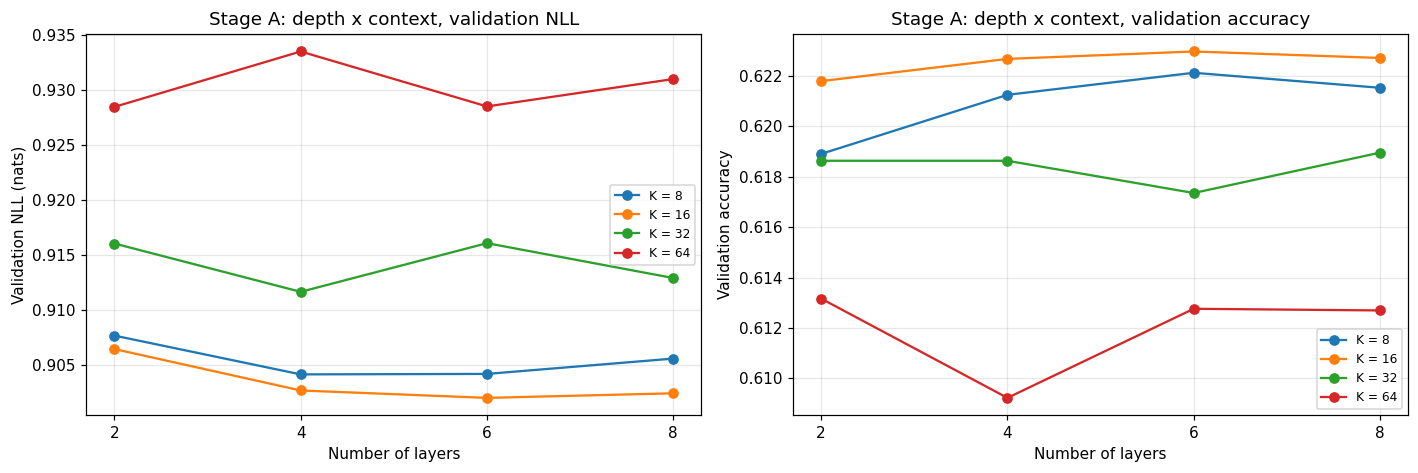

Mean over seeds, validation NLL (rows = layers, columns = K):
context_length      8       16      32      64
n_layers                                      
2               0.9077  0.9064  0.9160  0.9284
4               0.9041  0.9027  0.9116  0.9335
6               0.9042  0.9020  0.9161  0.9285
8               0.9056  0.9024  0.9129  0.9310


In [ ]:
pivot_nll = stage_a_summary.pivot(index="n_layers", columns="context_length", values="val_nll")
pivot_accuracy = stage_a_summary.pivot(index="n_layers", columns="context_length", values="val_accuracy")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for context_length in STAGE_A_CONTEXT:
    axes[0].plot(pivot_nll.index, pivot_nll[context_length], marker="o", label=f"K = {context_length}")
    axes[1].plot(pivot_accuracy.index, pivot_accuracy[context_length], marker="o", label=f"K = {context_length}")
axes[0].set_ylabel("Validation NLL (nats)")
axes[1].set_ylabel("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Number of layers")
    ax.set_xticks(STAGE_A_LAYERS)
    ax.legend(fontsize=8)
axes[0].set_title("Stage A: depth x context, validation NLL")
axes[1].set_title("Stage A: depth x context, validation accuracy")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_stage_a_depth_context.png", bbox_inches="tight")
plt.show()

print("Mean over seeds, validation NLL (rows = layers, columns = K):")
print(pivot_nll.round(4).to_string())

**What are we looking at?** Left: mean validation NLL (over seeds 0 and 1) against the number of layers, one line per context length. Right: the same for validation accuracy. The table under the figure gives the NLL values.

**What it shows.**

* K = 16 gives the lowest NLL at every depth (0.9064, 0.9027, 0.9020 and 0.9024 for 2, 4, 6 and 8 layers). K = 64 gives the highest at every depth (0.9284–0.9335).
* At K = 16, going from 2 to 4 layers lowers NLL from 0.9064 to 0.9027. The 4-, 6- and 8-layer values (0.9027, 0.9020, 0.9024) are close to one another.
* The effect of depth is not the same at every context length: at K = 32 and K = 64 the order of the 4- and 6-layer models is reversed, and at K = 64 the 4-layer model is the worst of the four depths. So depth and context length interact, which is why they were crossed rather than chosen one after the other.

**What it means.** Longer windows (32, 64) did not help at any depth tested, and depth beyond 4 layers made little difference at K = 16.

**What we cannot conclude.** These are two-seed means, and no significance test is applied. The seed SDs of these configurations are of the same order as many of the gaps between them (for example 0.0020 for 6 layers at K = 16). The formal comparisons are made later with five seeds per candidate and the match-level bootstrap.

In [ ]:
best_stage_a = stage_a_summary.iloc[0]
BEST_LAYERS = int(best_stage_a["n_layers"])
BEST_CONTEXT = int(best_stage_a["context_length"])
print(f"Lowest mean validation NLL in stage A: {best_stage_a['architecture']} "
      f"at {best_stage_a['val_nll']:.4f} (seed SD {best_stage_a['val_nll_sd']:.4f})")
print(f"Track A reference in the same table: "
      f"{stage_a_summary[(stage_a_summary['n_layers'] == BASE_LAYERS) & (stage_a_summary['context_length'] == BASE_CONTEXT)]['val_nll'].iloc[0]:.4f}")
print(f"Stage B and C will hold layers = {BEST_LAYERS} and K = {BEST_CONTEXT}.")

Lowest mean validation NLL in stage A: L6-H2-K16-D128-F512 at 0.9020 (seed SD 0.0020)
Track A reference in the same table: 0.9064
Stage B and C will hold layers = 6 and K = 16.


**RESULT.** The lowest mean validation NLL in stage A is L6-H2-K16-D128-F512 at 0.9020 (seed SD 0.0020). The Track A reference architecture (L2-H2-K16) reaches 0.9064 in the same table. Stages B and C are run at 6 layers and K = 16.

**Note.** "Lowest mean over two seeds" is a ranking. It decides where the remaining compute is spent. At K = 16 the 6-layer mean (0.9020) is below the 4-layer (0.9027) and 8-layer (0.9024) means by less than its own seed SD (0.0020).

## 8. Stage B — number of attention heads

**Hypothesis.** How the 128-dimensional attention width is split into heads changes how many separate attention patterns a layer can express, but not necessarily prediction quality.

**Control.** 6 layers and K = 16 from stage A; d_model stays 128, so the query, key, value and output projections have the same total size whatever the number of heads. The parameter count is identical (1,307,663) across this stage. Only the head dimension changes (128, 64, 32, 16 for 1, 2, 4, 8 heads).

In [ ]:
stage_b_rows = []
for n_heads in STAGE_B_HEADS:
    if BASE_D_MODEL % n_heads != 0:
        print(f"  skipped heads = {n_heads}: d_model {BASE_D_MODEL} is not divisible by it")
        continue
    for seed in SCREENING_SEEDS:
        config = transformer_config(seed, BEST_LAYERS, n_heads, BEST_CONTEXT)
        run_dir, result = run_one(config)
        stage_b_rows.append(result_row(config, run_dir, result, group="B heads"))
        print(f"  {architecture_label(config)} seed {seed}: "
              f"val NLL {result['val_metrics']['nll']:.4f} | acc {result['val_metrics']['accuracy']:.4f}")

capacity_table = append_results(stage_b_rows, CAPACITY_RUNS_CSV)
stage_b_summary = seed_level_to_config_level(capacity_table[capacity_table["group"] == "B heads"])
stage_b_summary[["architecture", "n_heads", "d_head", "parameters", "n_seeds", "val_nll", "val_nll_sd",
                 "val_accuracy", "val_macro_f1", "best_epoch", "runtime_seconds"]].round(4)

[transformer_T300_pre_action_L6_H1_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  1 | train loss 1.5218 | val NLL 1.0626 | val acc 0.5923 | val macro-F1 0.5119 | 10s
[transformer_T300_pre_action_L6_H1_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  2 | train loss 0.9990 | val NLL 0.9578 | val acc 0.6060 | val macro-F1 0.5335 | 10s
[transformer_T300_pre_action_L6_H1_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  3 | train loss 0.9336 | val NLL 0.9349 | val acc 0.6135 | val macro-F1 0.5457 | 11s
[transformer_T300_pre_action_L6_H1_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  4 | train loss 0.9088 | val NLL 0.9166 | val acc 0.6181 | val macro-F1 0.5499 | 11s
[transformer_T300_pre_action_L6_H1_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  5 | train loss 0.8921 | val NLL 0.9190 | val acc 0.6171 | val macro-F1 0.5535 | 11s
[transformer_T300_pre_action_L6_H1_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  6 | train loss 0.8800 | val NLL 0.9100 | val acc 0.6174 | val macro-F1 0.5556 | 10s
[transform

,architecture,n_heads,d_head,parameters,n_seeds,val_nll,val_nll_sd,val_accuracy,val_macro_f1,best_epoch,runtime_seconds
0,L6-H2-K16-D128-F512,2,64,1307663,2,0.9020,0.0020,0.6230,0.5566,7.5,139.6421
1,L6-H1-K16-D128-F512,1,128,1307663,2,0.9026,0.0001,0.6247,0.5615,8.0,140.2174
2,L6-H8-K16-D128-F512,8,16,1307663,2,0.9030,0.0010,0.6221,0.5600,8.0,144.2132
3,L6-H4-K16-D128-F512,4,32,1307663,2,0.9042,0.0001,0.6239,0.5593,8.0,145.1595


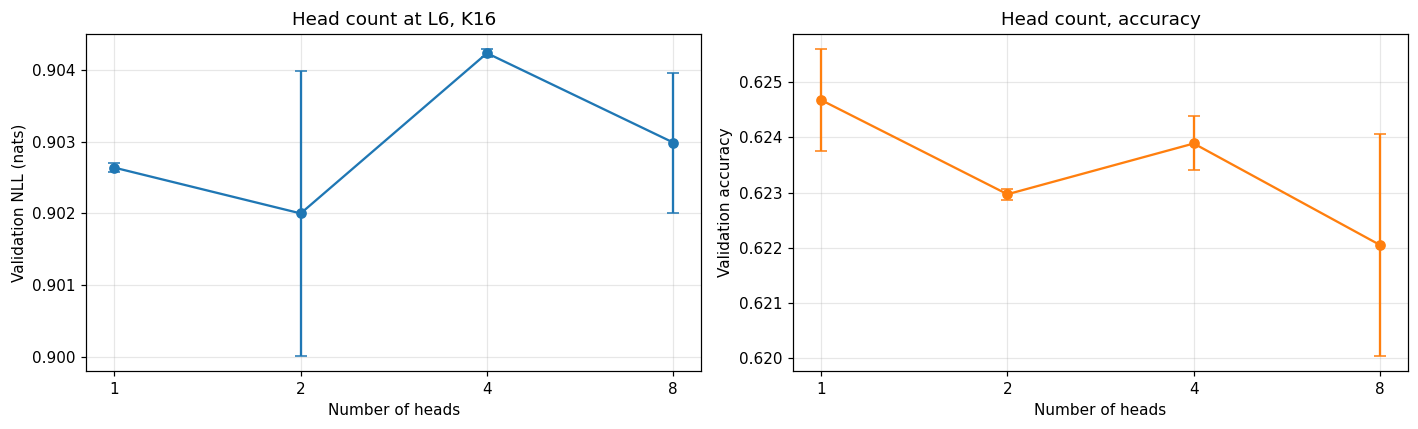

Lowest mean validation NLL: L6-H2-K16-D128-F512 at 0.9020
Spread across head counts: 0.0022 nats
Largest seed SD within a head count: 0.0020 nats


In [ ]:
ordered_heads = stage_b_summary.sort_values("n_heads")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.0))
axes[0].errorbar(ordered_heads["n_heads"], ordered_heads["val_nll"],
                 yerr=ordered_heads["val_nll_sd"].fillna(0), marker="o", capsize=4)
axes[0].set_ylabel("Validation NLL (nats)")
axes[0].set_title(f"Head count at L{BEST_LAYERS}, K{BEST_CONTEXT}")
axes[1].errorbar(ordered_heads["n_heads"], ordered_heads["val_accuracy"],
                 yerr=ordered_heads["val_accuracy_sd"].fillna(0), marker="o", capsize=4, color="tab:orange")
axes[1].set_ylabel("Validation accuracy")
axes[1].set_title("Head count, accuracy")
for ax in axes:
    ax.set_xlabel("Number of heads")
    ax.set_xscale("log", base=2)
    ax.set_xticks(ordered_heads["n_heads"])
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_stage_b_heads.png", bbox_inches="tight")
plt.show()

BEST_HEADS = int(stage_b_summary.iloc[0]["n_heads"])
print(f"Lowest mean validation NLL: {stage_b_summary.iloc[0]['architecture']} at {stage_b_summary.iloc[0]['val_nll']:.4f}")
print(f"Spread across head counts: {stage_b_summary['val_nll'].max() - stage_b_summary['val_nll'].min():.4f} nats")
print(f"Largest seed SD within a head count: {stage_b_summary['val_nll_sd'].max():.4f} nats")

**What are we looking at?** Validation NLL (left) and accuracy (right) against the number of heads at 6 layers and K = 16. Error bars are one standard deviation across the two screening seeds; with two values this is a rough indication of scale only.

**RESULT.** 2 heads: 0.9020, 1 head: 0.9026, 8 heads: 0.9030, 4 heads: 0.9042. The spread across head counts is 0.0022 nats; the largest seed SD within one head count is 0.0020 nats.

**INTERPRETATION.** The spread across head counts is about the same size as the seed spread within a head count. This screening cannot distinguish the head counts from one another, so the head count is left unresolved at this stage rather than reported as a finding. 2 heads (lowest mean) is carried into stage C.

## 9. Stage C — residual width and feed-forward width

Five (d_model, d_ff) combinations are trained at 6 layers, 2 heads and K = 16. Unlike the head count, width changes the parameter count substantially, in two different ways: d_model widens every embedding table, the attention projections and the MLP, while d_ff widens only the MLP. The pairs (128, 1024) and (256, 512) separate the two effects: the first raises only the feed-forward width, the second only the residual width.

Configurations whose d_model is not divisible by the head count would be skipped and reported (none is skipped with 2 heads).

In [ ]:
stage_c_rows = []
for d_model, d_ff in STAGE_C_WIDTHS:
    if d_model % BEST_HEADS != 0:
        print(f"  skipped d_model = {d_model}: not divisible by {BEST_HEADS} heads")
        continue
    for seed in SCREENING_SEEDS:
        config = transformer_config(seed, BEST_LAYERS, BEST_HEADS, BEST_CONTEXT, d_model=d_model, d_ff=d_ff)
        run_dir, result = run_one(config)
        stage_c_rows.append(result_row(config, run_dir, result, group="C width"))
        print(f"  {architecture_label(config)} seed {seed}: "
              f"val NLL {result['val_metrics']['nll']:.4f} | acc {result['val_metrics']['accuracy']:.4f} "
              f"| {result['parameter_counts']['total']:,} parameters")

capacity_table = append_results(stage_c_rows, CAPACITY_RUNS_CSV)
stage_c_summary = seed_level_to_config_level(capacity_table[capacity_table["group"] == "C width"])
stage_c_summary[["architecture", "d_model", "d_ff", "parameters", "n_seeds", "val_nll", "val_nll_sd",
                 "val_accuracy", "val_macro_f1", "best_epoch", "runtime_seconds"]].round(4)

  L6-H2-K16-D128-F512 seed 0: val NLL 0.9034 | acc 0.6229 | 1,307,663 parameters
  L6-H2-K16-D128-F512 seed 1: val NLL 0.9006 | acc 0.6230 | 1,307,663 parameters
[transformer_T300_pre_action_L6_H2_D128_F1024_K16_g-all_lr0.0003_wd0.1_s0] epoch  1 | train loss 1.5119 | val NLL 1.0680 | val acc 0.5934 | val macro-F1 0.5142 | 11s
[transformer_T300_pre_action_L6_H2_D128_F1024_K16_g-all_lr0.0003_wd0.1_s0] epoch  2 | train loss 1.0019 | val NLL 0.9645 | val acc 0.6032 | val macro-F1 0.5252 | 11s
[transformer_T300_pre_action_L6_H2_D128_F1024_K16_g-all_lr0.0003_wd0.1_s0] epoch  3 | train loss 0.9351 | val NLL 0.9369 | val acc 0.6091 | val macro-F1 0.5340 | 12s
[transformer_T300_pre_action_L6_H2_D128_F1024_K16_g-all_lr0.0003_wd0.1_s0] epoch  4 | train loss 0.9082 | val NLL 0.9188 | val acc 0.6187 | val macro-F1 0.5502 | 12s
[transformer_T300_pre_action_L6_H2_D128_F1024_K16_g-all_lr0.0003_wd0.1_s0] epoch  5 | train loss 0.8922 | val NLL 0.9135 | val acc 0.6189 | val macro-F1 0.5534 | 11s
[transfo

,architecture,d_model,d_ff,parameters,n_seeds,val_nll,val_nll_sd,val_accuracy,val_macro_f1,best_epoch,runtime_seconds
0,L6-H2-K16-D128-F512,128,512,1307663,2,0.9020,0.0020,0.6230,0.5566,7.5,139.6421
1,L6-H2-K16-D128-F1024,128,1024,2097167,2,0.9032,0.0013,0.6227,0.5634,10.0,173.4100
2,L6-H2-K16-D192-F768,192,768,2846223,2,0.9039,0.0028,0.6208,0.5592,6.0,144.5956
3,L6-H2-K16-D256-F512,256,512,3398671,2,0.9048,0.0054,0.6229,0.5556,4.0,126.1854
4,L6-H2-K16-D256-F1024,256,1024,4974607,2,0.9080,0.0006,0.6214,0.5502,4.5,159.4867


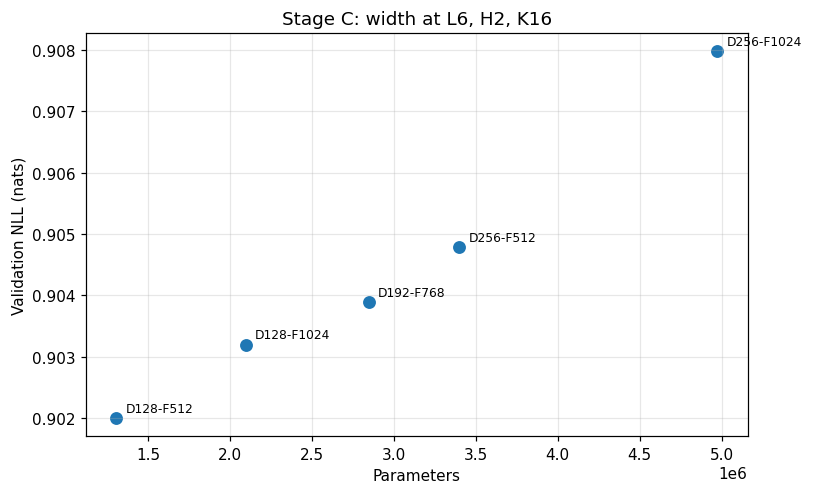

        architecture  parameters  val_nll  val_nll_sd  val_accuracy
 L6-H2-K16-D128-F512     1307663   0.9020      0.0020        0.6230
L6-H2-K16-D128-F1024     2097167   0.9032      0.0013        0.6227
 L6-H2-K16-D192-F768     2846223   0.9039      0.0028        0.6208
 L6-H2-K16-D256-F512     3398671   0.9048      0.0054        0.6229
L6-H2-K16-D256-F1024     4974607   0.9080      0.0006        0.6214


In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.scatter(stage_c_summary["parameters"], stage_c_summary["val_nll"], s=55)
for _, row in stage_c_summary.iterrows():
    ax.annotate(f"D{int(row['d_model'])}-F{int(row['d_ff'])}",
                (row["parameters"], row["val_nll"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("Parameters")
ax.set_ylabel("Validation NLL (nats)")
ax.set_title(f"Stage C: width at L{BEST_LAYERS}, H{BEST_HEADS}, K{BEST_CONTEXT}")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_stage_c_width.png", bbox_inches="tight")
plt.show()

print(stage_c_summary[["architecture", "parameters", "val_nll", "val_nll_sd", "val_accuracy"]].round(4).to_string(index=False))

**What are we looking at?** Mean validation NLL against parameter count for the five width configurations, each point labelled with its d_model and d_ff.

**RESULT.** The base width (128, 512; 1.31M parameters) has the lowest mean NLL, 0.9020. Every wider configuration is higher: (128, 1024) 0.9032 at 2.10M, (192, 768) 0.9039 at 2.85M, (256, 512) 0.9048 at 3.40M, and (256, 1024) 0.9080 at 4.97M. The d_model 256 runs reach their best validation NLL earlier (mean best epoch 4.0–4.5, against 7.5 at the base width).

**INTERPRETATION.** At 6 layers and K = 16, adding width up to about four times the parameters did not lower validation NLL. Raising only d_ff (128, 1024) and raising only d_model (256, 512) both left NLL above the base width.

**What we cannot conclude.** The differences among the first four widths are within the seed spread: (256, 512) has a seed SD of 0.0054 (its two seeds are 0.9086 and 0.9010). Only (256, 1024) is consistently higher on both seeds (0.9084 and 0.9076). Width was tested at one depth, one context length and the Track A learning rate and weight decay only.

## 10. Training curves

The curves below show training loss and validation NLL per epoch for a subset of the sweep: all depths at K = 16, and all context lengths at 6 layers (seed 0 only). Their purpose is diagnostic: a configuration still improving when its epoch budget ran out would have a result that understates what the architecture can reach, rather than one that reflcts a capacity limit.

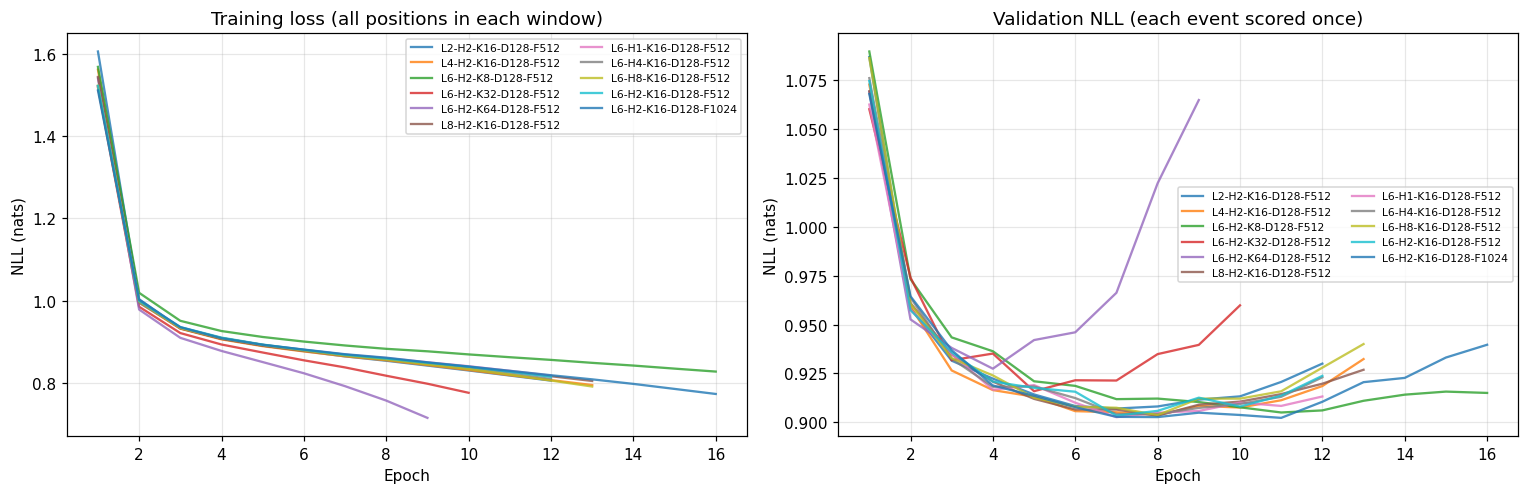

Configurations that used the full epoch budget without early stopping: 0
Configurations with a diverged run: 0


In [ ]:
curve_selection = capacity_table[
    ((capacity_table["context_length"] == BEST_CONTEXT) & (capacity_table["d_model"] == BASE_D_MODEL)) |
    ((capacity_table["n_layers"] == BEST_LAYERS) & (capacity_table["d_model"] == BASE_D_MODEL))
]
curve_selection = curve_selection[curve_selection["seed"] == SCREENING_SEEDS[0]]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for _, row in curve_selection.iterrows():
    history = analysis.load_history(Path(row["run_dir"]))
    axes[0].plot(history["epoch"], history["train_loss"], alpha=0.8, label=row["architecture"])
    axes[1].plot(history["epoch"], history["val_nll"], alpha=0.8, label=row["architecture"])
axes[0].set_title("Training loss (all positions in each window)")
axes[1].set_title("Validation NLL (each event scored once)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("NLL (nats)")
    ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_training_curves.png", bbox_inches="tight")
plt.show()

stopping = capacity_table.groupby("architecture").agg(
    best_epoch=("best_epoch", "mean"), epochs_run=("epochs_run", "mean"),
    stopped_early=("stopped_early", "all"), diverged=("diverged", "any")).reset_index()
at_budget = stopping[(~stopping["stopped_early"]) & (stopping["epochs_run"] >= EPOCH_BUDGET)]
print(f"Configurations that used the full epoch budget without early stopping: {len(at_budget)}")
if len(at_budget):
    print(at_budget.to_string(index=False))
print(f"Configurations with a diverged run: {int(stopping['diverged'].sum())}")

**What are we looking at?** Training loss (left, averaged over all positions of each window) and validation NLL (right, each event scored once), per epoch, one line per architecture.

**How to read it.** The two panels are not on exactly the same scale: training loss includes early window positions with little history, validation NLL scores each event with its maximal history. What matters here is where each validation curve reaches its minimum and whether it has flattened when training stops.

**RESULT.** No configuration used its full 30-epoch budget without early stopping, and no run diverged.

**INTERPRETATION.** Every run in the sweep stopped because validation NLL had stopped improving for 5 epochs. The results in the table are therefore not truncated by the epoch budget.

## 11. Consolidated sweep result and shortlist

All stages are combined into one table, one row per configuration (mean over the two screening seeds), ordered by mean validation NLL.

**Shortlist rule.** The architectures with the five lowest mean validation NLLs, plus the Track A reference architecture, which is always included so that every later comparison contains the current model. The shortlist size of five is a compute budget, not a statistical criterion (**PROVISIONAL**): it decides how many architectures receive a training-hyperparameter search and does not claim that the sixth architecture is worse.

In [ ]:
capacity_table = pd.read_csv(CAPACITY_RUNS_CSV)
full_summary = seed_level_to_config_level(capacity_table)
full_summary.to_csv(CAPACITY_SUMMARY_CSV, index=False)

SHORTLIST_SIZE = 5
shortlist = full_summary.head(SHORTLIST_SIZE).copy()

reference_mask = ((full_summary["n_layers"] == BASE_LAYERS) & (full_summary["n_heads"] == BASE_HEADS)
                  & (full_summary["context_length"] == BASE_CONTEXT) & (full_summary["d_model"] == BASE_D_MODEL)
                  & (full_summary["d_ff"] == BASE_D_FF))
reference_row = full_summary[reference_mask]
if len(reference_row) and reference_row.iloc[0]["architecture"] not in set(shortlist["architecture"]):
    shortlist = pd.concat([shortlist, reference_row], ignore_index=True)

top_configs = []
for _, row in shortlist.iterrows():
    top_configs.append({"architecture": row["architecture"], "n_layers": int(row["n_layers"]),
                        "n_heads": int(row["n_heads"]), "context_length": int(row["context_length"]),
                        "d_model": int(row["d_model"]), "d_ff": int(row["d_ff"]),
                        "parameters": int(row["parameters"]), "screening_val_nll": float(row["val_nll"]),
                        "screening_val_nll_sd": (None if pd.isna(row["val_nll_sd"]) else float(row["val_nll_sd"])),
                        "is_track_a_reference": bool(row["architecture"] == architecture_label(
                            transformer_config(0, BASE_LAYERS, BASE_HEADS, BASE_CONTEXT)))})
training.save_json(TOP_CONFIGS_JSON, {"shortlist_size": SHORTLIST_SIZE,
                                      "shortlist_size_origin": "compute budget for notebook 09; provisional",
                                      "screening_seeds": SCREENING_SEEDS,
                                      "stage_a_best": {"n_layers": BEST_LAYERS, "context_length": BEST_CONTEXT},
                                      "stage_b_best_heads": BEST_HEADS,
                                      "configurations": top_configs})

print(f"Configurations trained: {len(full_summary)} | runs: {len(capacity_table)}")
print(f"Total sweep compute: {capacity_table['runtime_seconds'].sum() / 3600:.2f} GPU-hours")
print("\nShortlist written to", TOP_CONFIGS_JSON)
full_summary[["architecture", "group", "parameters", "n_seeds", "val_nll", "val_nll_sd", "val_accuracy",
              "val_macro_f1", "val_top3", "val_top5", "val_ece", "best_epoch", "runtime_seconds"]].round(4)

Configurations trained: 23 | runs: 46
Total sweep compute: 1.82 GPU-hours

Shortlist written to /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/results/08_top_configs.json


,architecture,group,parameters,n_seeds,val_nll,val_nll_sd,val_accuracy,val_macro_f1,val_top3,val_top5,val_ece,best_epoch,runtime_seconds
0,L6-H2-K16-D128-F512,C width,1307663,2,0.9020,0.0020,0.6230,0.5566,0.9487,0.9944,0.0209,7.5,139.6421
1,L8-H2-K16-D128-F512,A depth x context,1704207,2,0.9024,0.0014,0.6227,0.5634,0.9482,0.9943,0.0236,8.5,190.6625
2,L6-H1-K16-D128-F512,B heads,1307663,2,0.9026,0.0001,0.6247,0.5615,0.9485,0.9944,0.0231,8.0,140.2174
3,L4-H2-K16-D128-F512,A depth x context,911119,2,0.9027,0.0014,0.6227,0.5631,0.9481,0.9942,0.0198,8.0,105.9108
4,L6-H8-K16-D128-F512,B heads,1307663,2,0.9030,0.0010,0.6221,0.5600,0.9478,0.9944,0.0190,8.0,144.2132
5,L6-H2-K16-D128-F1024,C width,2097167,2,0.9032,0.0013,0.6227,0.5634,0.9483,0.9942,0.0301,10.0,173.4100
6,L6-H2-K16-D192-F768,C width,2846223,2,0.9039,0.0028,0.6208,0.5592,0.9483,0.9945,0.0215,6.0,144.5956
7,L4-H2-K8-D128-F512,A depth x context,910095,2,0.9041,0.0015,0.6213,0.5587,0.9478,0.9944,0.0224,12.5,130.7011
8,L6-H2-K8-D128-F512,A depth x context,1306639,2,0.9042,0.0012,0.6221,0.5622,0.9476,0.9942,0.0154,12.0,177.3726
9,L6-H4-K16-D128-F512,B heads,1307663,2,0.9042,0.0001,0.6239,0.5593,0.9482,0.9944,0.0233,8.0,145.1595


**What the table contains.** One row per configuration (23 in total), averaged over seeds 0 and 1: architecture, parameter count, the six validation metrics (NLL, accuracy, macro-F1, top-3, top-5, ECE), mean best epoch and mean runtime.

**RESULT.** The five lowest mean validation NLLs are L6-H2-K16 (0.9020), L8-H2-K16 (0.9024), L6-H1-K16 (0.9026), L4-H2-K16 (0.9027) and L6-H8-K16 (0.9030). All five use K = 16 and the base width. The Track A reference architecture L2-H2-K16 is 13th of 23 at 0.9064 and is added to the shortlist as the sixth entry.

**OBSERVATION.** The top five lie between 0.9020 and 0.9030, a range smaller than the largest seed SD among them (0.0020). The bottom of the table is made up of the K = 32 and K = 64 configurations.


In [ ]:
final_check = {
    "runs_recorded": int(len(capacity_table)),
    "configurations": int(len(full_summary)),
    "any_diverged": bool(capacity_table["diverged"].any()),
    "sweep_gpu_hours": float(capacity_table["runtime_seconds"].sum() / 3600),
    "best_architecture_by_val_nll": str(full_summary.iloc[0]["architecture"]),
    "best_val_nll": float(full_summary.iloc[0]["val_nll"]),
    "track_a_reference_val_nll": (float(reference_row.iloc[0]["val_nll"]) if len(reference_row) else None),
    "test_split_touched": False,
}
training.save_json(RESULTS_DIR / "08_summary.json", final_check)

modified = [name for name, digest in json.load(open(MANIFEST_DIR / "track_a_snapshot.json")).items()
            if (EXISTING_DIR / name).exists() and file_sha256(EXISTING_DIR / name) != digest]
print("Track A result files modified by this notebook:", modified if modified else "none")
print(json.dumps(final_check, indent=2))

Track A result files modified by this notebook: none
{
  "runs_recorded": 46,
  "configurations": 23,
  "any_diverged": false,
  "sweep_gpu_hours": 1.8223664838737912,
  "best_architecture_by_val_nll": "L6-H2-K16-D128-F512",
  "best_val_nll": 0.9019999504089355,
  "track_a_reference_val_nll": 0.9064347743988038,
  "test_split_touched": false
}


## 12. Summary

| Item | Result |
|---|---|
| Code compatibility with the Track A checkpoint | reproduced exactly (logit difference 0.0) |
| Runs | 46 (23 configurations × seeds 0, 1); none diverged; none used the full epoch budget |
| Compute | 1.82 GPU-hours on a Tesla T4 |
| Depth × context | K = 16 best at every depth; at K = 16, 2 layers 0.9064, 4 layers 0.9027, 6 layers 0.9020, 8 layers 0.9024 |
| Heads | spread 0.0022 nats, comparable to seed SD (0.0020); unresolved |
| Width | no wider configuration below the base width (128, 512) |
| Lowest mean validation NLL | L6-H2-K16-D128-F512, 0.9020 (Track A architecture: 0.9064) |
| Shortlist | L6-H2-K16, L8-H2-K16, L6-H1-K16, L4-H2-K16, L6-H8-K16, plus the Track A architecture L2-H2-K16 |
| Track A files modified | none |
| Test split | not accessed |

Files produced: `results/08_capacity_runs.csv` (one row per run) and `results/08_capacity_summary.csv` (one row per configuration); `results/08_profile.csv` (measured GPU memory and step time); `results/08_top_configs.json` (the shortlist, which decides which architectures receive the training-hyperparameter search).

**Limitations.** Two seeds per configuration; staged; all runs at the Track A learning rate and weight decay, so an architecture that would prefer other training settings may be disadvantaged here.